# 06 Objectives

Notebooks 02 to 05 trained every LightGBM model with its default objective, L2. The objective decides which number the model aims for, so this notebook asks four questions:

1. What do different objectives aim for? A five-number example.
2. What does our demand look like: how skewed, how many zero weeks?
3. What does the Tweedie objective assume, and why might it suit sales?
4. How do the objectives compare on our data, overall, on intermittent products, with target standardization, and with the drivers of notebook 03?

Sections 1 to 3 run in seconds, sections 4 to 6 in about a minute, section 7 in about two minutes.

In [1]:
import os
import sys
import warnings

if "google.colab" in sys.modules:
    !git clone -q https://github.com/tackes/time-series-forecasting-bootcamp
    %cd time-series-forecasting-bootcamp
    %pip install -q statsforecast==2.1.1 mlforecast==1.1.0 utilsforecast==0.2.17 lightgbm==4.7.0 catboost==1.2.10
elif not os.path.exists("shared"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

In [2]:
import time

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from mlforecast import MLForecast
from mlforecast.target_transforms import LocalStandardScaler

from shared.prepare_data import load_panel, H, FREQ, ALL_CUTOFFS, DEV_CUTOFFS, TEST_CUTOFF
from shared.features import LAGS, LAG_TRANSFORMS, DATE_FEATURES, LGB_PARAMS
from shared.evaluation import score
from shared.leaderboard import to_long, save_forecasts, load_forecasts, leaderboard

panel = load_panel()
actuals = panel[["unique_id", "ds", "y"]]

## 1. Objective functions on five numbers

A product sells 10 units a week for four weeks, then 60 in a promotion week. Suppose we must forecast one number for all five weeks. Which number is best depends on how we score the misses.

In [3]:
y = np.array([10, 10, 10, 10, 60])
print(f"mean {y.mean():.0f}, median {np.median(y):.0f}")

mean 20, median 10


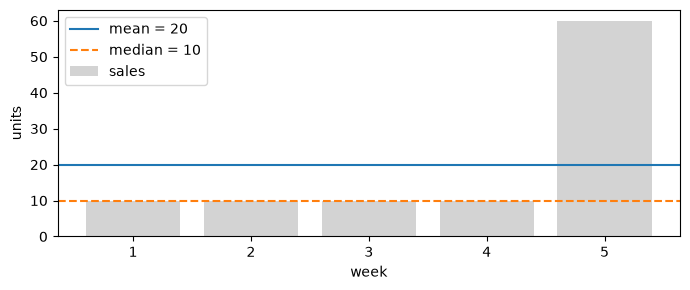

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(1, 6), y, color="lightgrey", label="sales")
ax.axhline(y.mean(), color="C0", label=f"mean = {y.mean():.0f}")
ax.axhline(np.median(y), color="C1", ls="--", label=f"median = {np.median(y):.0f}")
ax.set(xlabel="week", ylabel="units")
ax.legend()
plt.tight_layout()

Two ways to score a constant forecast `f`:

- **L2 (MSE)**, the mean of the squared misses `(y - f)**2`. LightGBM's default.
- **L1 (MAE)**, the mean of the absolute misses `|y - f|`.

Five candidate forecasts:

In [118]:
guesses = [10, 15, 20, 30, 60]
pd.DataFrame({
    "L2 (MSE)": [np.mean((y - f) ** 2) for f in guesses],
    "L1 (MAE)": [np.mean(np.abs(y - f)) for f in guesses],
}, index=pd.Index(guesses, name="forecast"))

,L2 (MSE),L1 (MAE)
forecast,,
10,500.0,10.0
15,425.0,13.0
20,400.0,16.0
30,500.0,22.0
60,2000.0,40.0


L2 is lowest at 20 and L1 at 10. The same two losses for every forecast between 0 and 60:

The L2 minimum is the mean and the L1 minimum is the median. Squaring makes the 40-unit miss on the spike week cost 1,600, so L2 moves the forecast towards the spike. L1 charges the spike only 40, and moving up would cost more on the four ordinary weeks than it saves on the one spike.


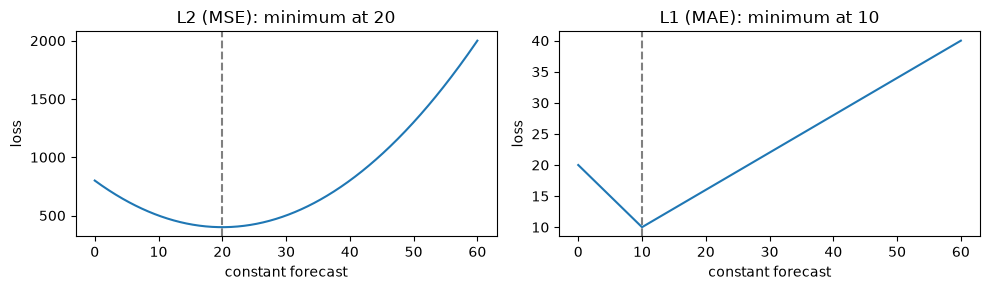

In [6]:
grid = np.linspace(0, 60, 601)
l2 = ((y[:, None] - grid) ** 2).mean(axis=0)
l1 = np.abs(y[:, None] - grid).mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, loss, name in [(axes[0], l2, "L2 (MSE)"), (axes[1], l1, "L1 (MAE)")]:
    ax.plot(grid, loss)
    ax.axvline(grid[loss.argmin()], color="grey", ls="--")
    ax.set(title=f"{name}: minimum at {grid[loss.argmin()]:.0f}", xlabel="constant forecast", ylabel="loss")
plt.tight_layout()

### Penalty for an additional unit of error

- **L1 (MAE):** Every additional unit of error carries the same penalty.
- **L2 (MSE):** The penalty increases as the existing error grows.

This is why MSE is more sensitive to large errors and outliers,
while MAE is more robust to demand spikes.

In [7]:
errors = np.array([0, 1, 5, 10, 50, 100])

pd.DataFrame({
    "Error increase": [f"{e} → {e+1}" for e in errors],
    "Additional L1 penalty": (errors + 1) - errors,
    "Additional L2 penalty": (errors + 1)**2 - errors**2
})

,Error increase,Additional L1 penalty,Additional L2 penalty
0,0 → 1,1,1
1,1 → 2,1,3
2,5 → 6,1,11
3,10 → 11,1,21
4,50 → 51,1,101
5,100 → 101,1,201


### Conditional mean and conditional median

A model gives one number per situation, not one number overall: per combination of lags, calendar and, later, price and promotion features `x`.

- L2 aims at the **conditional mean**, the average sales that follow situation `x`.
- L1 aims at the **conditional median**, the typical sales that follow situation `x`.

If the features can tell spike weeks from ordinary weeks, the spikes get their own situations and both objectives can forecast them. If they cannot, the spikes stay mixed into ordinary situations. L2 then raises the forecast for every such week a little, and L1 forecasts an ordinary week.

### Quantile Loss

MAE penalizes overforecasting and underforecasting equally.
Quantile loss allows us to penalize one more than the other.

- **alpha = 0.5:** Equal penalty (targets the median).
- **alpha = 0.6:** Underforecasting is penalized more.
- **alpha = 0.9:** Underforecasting is penalized much more.

A higher alpha encourages higher forecasts, which can be
useful when stockouts are more costly than excess inventory.

In [8]:
def pinball(y, f, alpha):
    """Quantile loss of a constant forecast f at level alpha."""
    return np.mean(np.maximum(alpha * (y - f), (alpha - 1) * (y - f)))

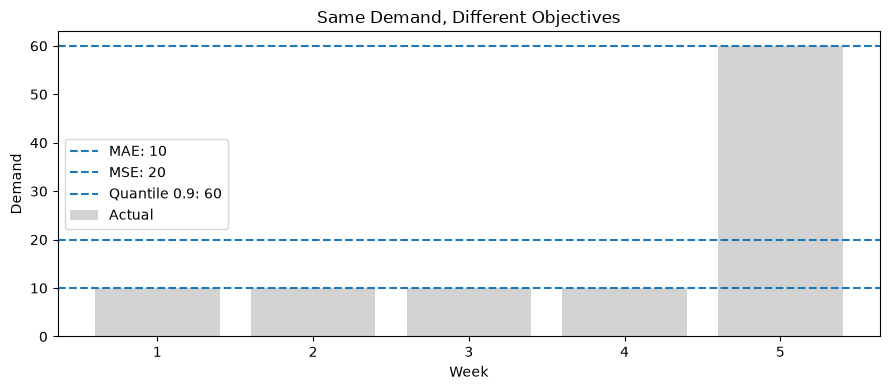

In [9]:
forecasts = {
    "MAE": np.median(y),
    "MSE": np.mean(y),
    "Quantile 0.9": grid[np.argmin(
        [pinball(y, f, 0.9) for f in grid]
    )]
}

plt.figure(figsize=(9, 4))
plt.bar(range(1, len(y) + 1), y,
        color="lightgrey", label="Actual")

for name, f in forecasts.items():
    plt.axhline(f, linestyle="--", label=f"{name}: {f:.0f}")

plt.xlabel("Week")
plt.ylabel("Demand")
plt.title("Same Demand, Different Objectives")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
pd.DataFrame({
    name: {
        "Forecast": f,
        "WAPE (%)": 100 * np.abs(y - f).sum() / y.sum(),
        "Bias (%)": 100 * (f - y).sum() / y.sum(),
        "P90 Loss": pinball(y, f, 0.9)
    }
    for name, f in forecasts.items()
}).T.round(2)

,Forecast,WAPE (%),Bias (%),P90 Loss
MAE,10.0,50.0,-50.0,9.0
MSE,20.0,80.0,0.0,8.0
Quantile 0.9,60.0,200.0,200.0,4.0


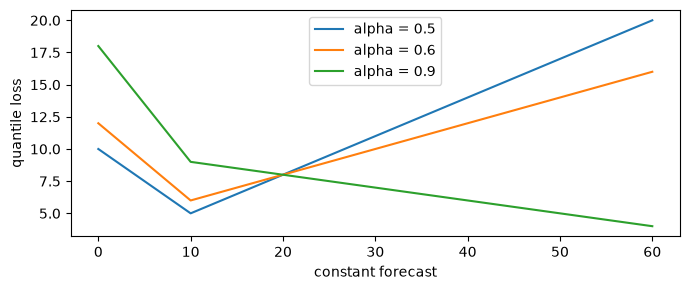

In [11]:
fig, ax = plt.subplots(figsize=(7, 3))
for alpha in [0.5, 0.6, 0.9]:
    ax.plot(grid, [pinball(y, f, alpha) for f in grid], label=f"alpha = {alpha}")
ax.set(xlabel="constant forecast", ylabel="quantile loss")
ax.legend()
plt.tight_layout()

In our example, the optimal forecast jumps from 10 to 60
when alpha exceeds 0.8. We will test alpha = 0.6 to see
whether slightly higher forecasts improve performance.

### Relationship to WAPE

WAPE measures absolute error, which is what L1 minimizes
when training on the original sales scale.

- **L1:** Targets the median.
- **L2 and Tweedie:** Target the mean.
- **Quantile:** Allows us to target higher or lower forecasts.

For right-skewed demand, the median is typically below
the mean, which can lead to negative forecast bias.

## 2. What our demand looks like

Each product is described by its own history up to the last development cutoff, 2025-01-01, so nothing here uses a later week. The statistics are within each product. Pooling raw sales across products would mostly show which products are large, because weekly sales differ by orders of magnitude between them.

In [12]:
profile_cutoff = DEV_CUTOFFS[-1]
history = actuals[actuals.ds <= profile_cutoff]
profile = history.assign(zero=history.y == 0).groupby("unique_id").agg(mean=("y", "mean"), zero_share=("zero", "mean"), skewness=("y", "skew"))
profile.describe().round(2)

,mean,zero_share,skewness
count,2000.00,2000.00,2000.00
mean,3992.07,0.21,1.25
std,15295.52,0.29,1.55
min,0.00,0.00,-2.14
25%,110.28,0.00,0.22
50%,751.00,0.10,1.05
75%,3040.48,0.24,1.92
max,438278.94,1.00,8.89


**Skewness** measures the asymmetry of a distribution:

- < 0: Negative (left-skewed) — occasional low sales
- ≈ 0: Little or no skewness
- > 0: Positive (right-skewed) — occasional high sales

Products that never sold are excluded because their
sales have no variation, making skewness undefined.

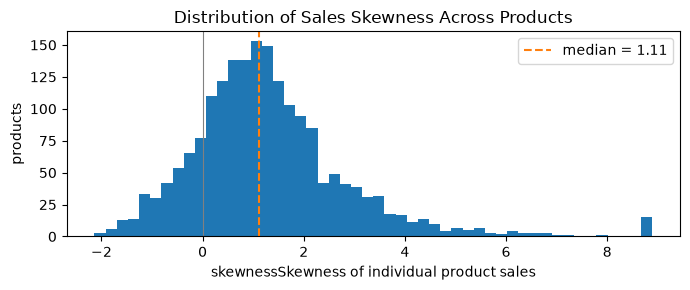

In [13]:
sold = profile[profile["mean"] > 0]
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(sold.skewness, bins=50, color="C0")
ax.axvline(0, color="grey", lw=0.8)
ax.axvline(sold.skewness.median(), color="C1", ls="--", label=f"median = {sold.skewness.median():.2f}")
ax.set(xlabel="skewnessSkewness of individual product sales", ylabel="products", title="Distribution of Sales Skewness Across Products")
ax.legend()
plt.tight_layout()

**Zero-sales share** is the share of a product's weeks with no sales.

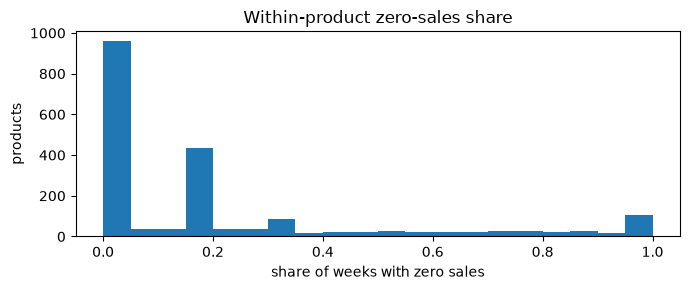

In [14]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(profile.zero_share, bins=20, range=(0, 1), color="C0")
ax.set(xlabel="share of weeks with zero sales", ylabel="products", title="Within-product zero-sales share")
plt.tight_layout()

Intermittency bands, with the bounds of notebook 02 and the zero-heavy group split at 90%: **regular** (up to 10% zero weeks), **some zeros** (10 to 50%), **zero heavy** (50 to 90%), **rarely sells** (over 90%, including products that never sold). The volume share is each band's share of total units sold.

In [15]:
BAND_EDGES = [-0.01, 0.1, 0.5, 0.9, 1]
BANDS = ["regular", "some_zeros", "zero_heavy", "rarely_sells"]

band = pd.cut(profile.zero_share, BAND_EDGES, labels=BANDS)
volume = history.groupby("unique_id").y.sum()
pd.DataFrame({
    "products": band.value_counts(sort=False),
    "product_share": band.value_counts(normalize=True, sort=False),
    "volume_share": volume.groupby(band, observed=False).sum() / volume.sum(),
}).round(3)

,products,product_share,volume_share
zero_share,,,
regular,995,0.498,0.722
some_zeros,690,0.345,0.270
zero_heavy,192,0.096,0.007
rarely_sells,123,0.062,0.000


Half the products are regular and carry 72% of the units. The two zero-heavy bands hold 16% of the products but under 1% of the units. WAPE divides total error by total sales, so these products barely move an aggregate WAPE: an objective could be much better on them and still lose overall.

Two features of these histograms come from how the data were recorded, not only from demand:

- **58% of all zero weeks fall before a product's first sale.** For a newer product, the zero share partly measures how recently it launched. Of the 123 products that rarely sell, 86 had not sold at all by this cutoff.
- **About 350 products have one run of exactly 13 zero weeks starting at a quarter boundary**, which causes the peak at 15 to 20% zero weeks. That looks like a missing quarter of data rather than 13 weeks without demand. It is not investigated here.

The small pile-up at a skewness near 9 is a dozen products with a single week of sales.

Three example products, picked by rules on the same history:

- **regular**: no zero weeks, skewness closest to the median of such products.
- **spiky**: at most 10% zero weeks, skewness at the 95th percentile of such products.
- **intermittent**: zero heavy, zero-sales share closest to the band's median.

In [16]:
regular = profile[profile.zero_share == 0]
mostly_selling = profile[profile.zero_share <= 0.1]
zero_heavy = profile[band == "zero_heavy"]
examples = {
    "regular": (regular.skewness - regular.skewness.median()).abs().idxmin(),
    "spiky": (mostly_selling.skewness - mostly_selling.skewness.quantile(0.95)).abs().idxmin(),
    "intermittent": (zero_heavy.zero_share - zero_heavy.zero_share.median()).abs().idxmin(),
}
profile.loc[list(examples.values())].assign(kind=list(examples)).round(2)

,mean,zero_share,skewness,kind
unique_id,,,,
5257_S1,544.18,0.00,1.11,regular
13201_S1,1028.89,0.06,3.36,spiky
11440_S1,2.53,0.73,2.63,intermittent


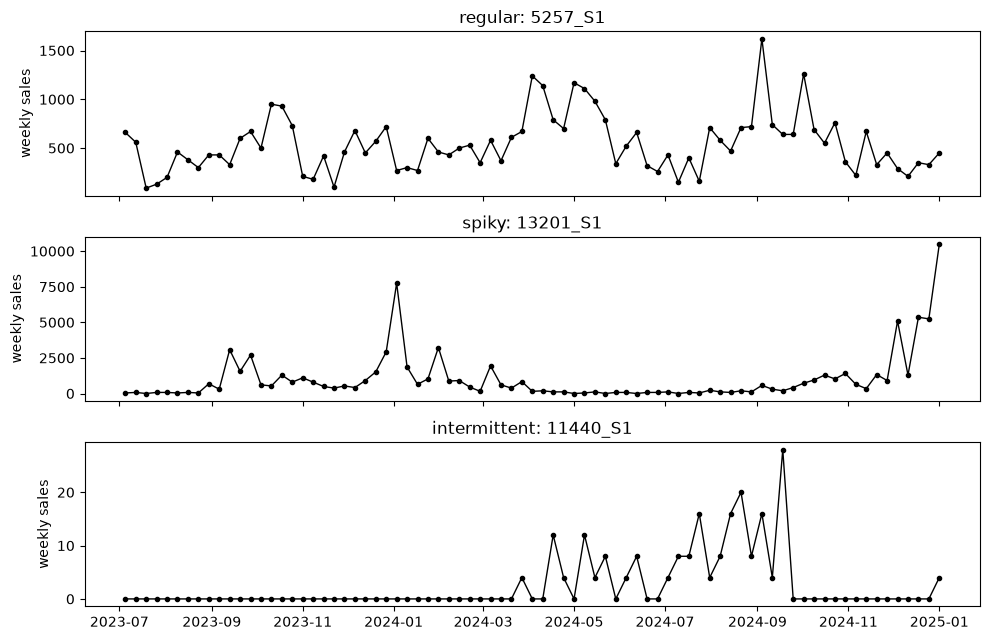

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
for ax, (kind, sku) in zip(axes, examples.items()):
    series = history[history.unique_id == sku]
    ax.plot(series.ds, series.y, marker=".", color="black", lw=1)
    ax.set(title=f"{kind}: {sku}", ylabel="weekly sales")
plt.tight_layout()

The regular product varies around a stable level. The spiky product has a few weeks at five to ten times its usual level. The intermittent product has both kinds of zero: about nine months before its first sale, then gaps between small sales, then a quarter with none.

### Tweedie Loss

Tweedie is an alternative to L2 that:

- Targets the mean rather than the median.
- Accommodates zero and positive continuous demand.
- Accounts for increasing variance as demand grows.

The variance power (p) controls how quickly variance
increases with the mean.

We will test p = 1.3.

In [18]:
mu, phi, p = 5.0, 5.0, 1.3
rate = mu ** (2 - p) / (phi * (2 - p))          # Poisson rate of purchase events
shape, scale = (2 - p) / (p - 1), phi * (p - 1) * mu ** (p - 1)  # gamma size of each event

rng = np.random.default_rng(0)
events = rng.poisson(rate, 100_000)
draws = np.where(events > 0, rng.gamma(np.maximum(events, 1) * shape, scale), 0.0)
print(f"mean {draws.mean():.2f}, exact zeros {np.mean(draws == 0):.0%}, 99th percentile {np.quantile(draws, 0.99):.1f}")

mean 5.00, exact zeros 41%, 99th percentile 26.2


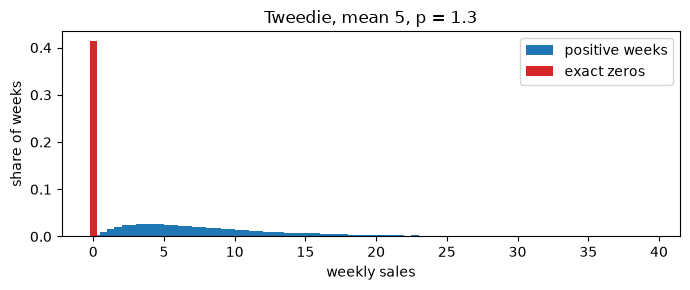

In [19]:
positive = draws[draws > 0]
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(positive, bins=np.arange(0, 40, 0.5), weights=np.full(len(positive), 1 / len(draws)), color="C0", label="positive weeks")
ax.bar(0, np.mean(draws == 0), width=0.5, color="C3", label="exact zeros")
ax.set(xlabel="weekly sales", ylabel="share of weeks", title=f"Tweedie, mean {mu:.0f}, p = {p}")
ax.legend()
plt.tight_layout()

### Variance grows with the mean

The Tweedie family is defined by its mean-variance relationship

`Var(Y|X) = phi * mu**p`

where `mu` is the conditional mean, `phi` a dispersion and `p` the variance power. `p = 0` is the normal distribution with constant variance, the assumption behind L2; `p = 1` is Poisson; `p = 2` is gamma, where the standard deviation is proportional to the mean.

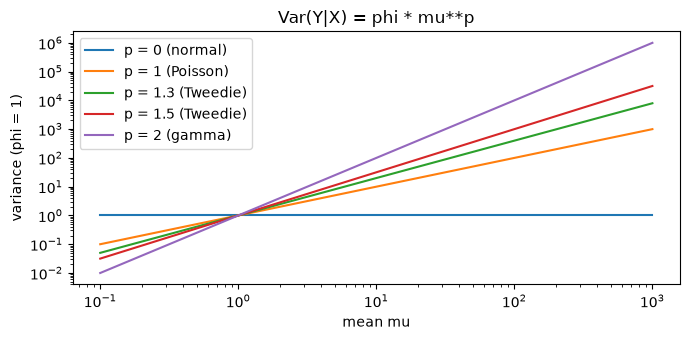

In [20]:
means = np.logspace(-1, 3, 100)
fig, ax = plt.subplots(figsize=(7, 3.5))
for power, name in [(0, "normal"), (1, "Poisson"), (1.3, "Tweedie"), (1.5, "Tweedie"), (2, "gamma")]:
    ax.plot(means, 1.0 * means ** power, label=f"p = {power} ({name})")
ax.set(xscale="log", yscale="log", xlabel="mean mu", ylabel="variance (phi = 1)", title="Var(Y|X) = phi * mu**p")
ax.legend()
plt.tight_layout()

In [21]:
means = np.array([5, 10, 100, 1000])
phi = 1

powers = {
    "Normal (p=0)": 0,
    "Poisson (p=1)": 1,
    "Tweedie (p=1.3)": 1.3,
    "Tweedie (p=1.5)": 1.5,
    "Gamma (p=2)": 2
}

pd.DataFrame({
    name: phi * means.astype(float)**p
    for name, p in powers.items()
}, index=means).rename_axis("Expected weekly sales").round(1)

,Normal (p=0),Poisson (p=1),Tweedie (p=1.3),Tweedie (p=1.5),Gamma (p=2)
Expected weekly sales,,,,,
5,1.0,5.0,8.1,11.2,25.0
10,1.0,10.0,20.0,31.6,100.0
100,1.0,100.0,398.1,1000.0,10000.0
1000,1.0,1000.0,7943.3,31622.8,1000000.0


### Mean-variance relationship

The variance power `p` controls how quickly expected demand
variance increases as mean demand increases.

The table below illustrates this relationship assuming
dispersion (phi) = 1.

Larger-volume products typically have larger absolute fluctuations in demand. Tweedie accounts for this by allowing variance to increase with expected sales. The variance power controls how quickly it increases. Tweedie changes how errors are weighted at different demand levels, while still targeting the conditional mean.


### Why Tweedie can suit demand

- **Non-negative with exact zeros.** Sales are never negative, and the zero weeks of intermittent products are part of the distribution, not outliers.
- **Skewed.** The gamma part has a long right tail, like promotion weeks.
- **Variance that grows with the level.** A product selling 1,000 a week swings by more units than one selling 10. Tweedie expects that and weighs errors on large values relatively less than L2 does.
- **Log link.** LightGBM's Tweedie objective predicts `exp(score)`, so forecasts are always positive and effects are multiplicative.

Like L2, Tweedie estimates the conditional **mean**. It is a better-matched assumption about the noise, not a different target, and WAPE rewards the median. Whether it helps depends on how well the assumption fits; it does not by itself make a model better on intermittent data.

### Tweedie needs the raw target

Notebook 02's `LocalStandardScaler` replaces each product's sales with `(y - mean) / std`. Every below-average week becomes negative, and a zero week becomes `-mean / std`, a different negative number for each product. The Tweedie likelihood is defined only for `y >= 0`:

In [22]:
z = history.groupby("unique_id").y.transform(lambda s: (s - s.mean()) / s.std())
print(f"standardized training values below zero: {(z < 0).mean():.0%}")

try:
    lgb.LGBMRegressor(objective="tweedie", n_estimators=1, verbosity=-1).fit(np.arange(3.0).reshape(-1, 1), [-1.0, 0.0, 1.0])
except lgb.basic.LightGBMError as error:
    print("LightGBM:", error)

standardized training values below zero: 56%
LightGBM: [tweedie]: at least one target label is negative


So Tweedie is compared on the raw target only.

## 4. Four objectives on the raw target

Every model uses the lags, rolling means and calendar features of notebook 02, these LightGBM parameters and the same ten origins. Only the objective and its own parameter change. The target is raw units, the only scale Tweedie accepts.

In [23]:
LGB_PARAMS

{'n_estimators': 300,
 'learning_rate': 0.05,
 'num_leaves': 31,
 'min_child_samples': 50,
 'subsample': 0.8,
 'subsample_freq': 1,
 'colsample_bytree': 0.8,
 'random_state': 0,
 'verbosity': -1}

The L2 model is `lgbm_raw` from notebook 02, fit with exactly this configuration and the default objective, so it is loaded rather than refit. MLForecast trains each model in `models` on the same features.

In [24]:
mlf_raw = MLForecast(
    models={
        # "lgbm_raw": lgb.LGBMRegressor(**LGB_PARAMS),  L2, fit in notebook 02
        "lgbm_l1_raw": lgb.LGBMRegressor(**LGB_PARAMS, objective="l1"),
        "lgbm_tweedie_raw": lgb.LGBMRegressor(**LGB_PARAMS, objective="tweedie", tweedie_variance_power=1.3),
        "lgbm_quantile60_raw": lgb.LGBMRegressor(**LGB_PARAMS, objective="quantile", alpha=0.6),
    },
    freq=FREQ,
    lags=LAGS,
    lag_transforms=LAG_TRANSFORMS,
    date_features=DATE_FEATURES,
    num_threads=1,
)

In [25]:
start = time.perf_counter()
raw_forecasts = []
for cutoff in ALL_CUTOFFS:
    mlf_raw.fit(actuals[actuals.ds <= cutoff])
    raw_forecasts.append(to_long(mlf_raw.predict(H), cutoff, "06_objectives"))
raw_forecasts = pd.concat(raw_forecasts)
print(f"{time.perf_counter() - start:.0f} s for three models at {len(ALL_CUTOFFS)} origins")

21 s for three models at 10 origins


One table: development scores over the seven development origins, the final 14 weeks (exploratory), and the number of development origins at which each objective beats L2.

In [26]:
OBJECTIVE = {"lgbm_raw": "L2", "lgbm_l1_raw": "L1", "lgbm_tweedie_raw": "Tweedie 1.3", "lgbm_quantile60_raw": "quantile 0.6"}
raw = pd.concat([load_forecasts(["02_ml_baseline"]).query("model == 'lgbm_raw'"), raw_forecasts])

dev = leaderboard(raw, actuals, scope="dev").set_index("model")
final = leaderboard(raw, actuals, scope="test").set_index("model")
origin_wape = score(raw[raw.cutoff.isin(DEV_CUTOFFS)], actuals, by=["cutoff"], rmsse=False).pivot(index="model", columns="cutoff", values="wape")

raw_table = pd.DataFrame({"objective": OBJECTIVE}).join(dev[["wape", "mae", "bias", "mean_rmsse", "median_rmsse"]])
raw_table = raw_table.join(final[["wape", "bias"]].add_prefix("final_"))
raw_table["better_than_L2_at"] = (origin_wape.lt(origin_wape.loc["lgbm_raw"], axis=1)).sum(axis=1)
raw_table.round(3)

,objective,wape,mae,bias,mean_rmsse,median_rmsse,final_wape,final_bias,better_than_L2_at
lgbm_raw,L2,0.456,1912.592,0.044,5.501,1.224,0.505,0.215,0
lgbm_l1_raw,L1,0.409,1714.512,-0.143,1.757,0.858,0.375,-0.073,7
lgbm_tweedie_raw,Tweedie 1.3,0.432,1813.335,0.008,1.918,0.951,0.455,0.147,7
lgbm_quantile60_raw,quantile 0.6,0.433,1816.541,-0.006,1.839,0.940,0.433,0.080,7


- L1 delivers the best accuracy but underforecasts by 14.3%.
- Tweedie and quantile loss sacrifice some accuracy to achieve
nearly unbiased forecasts.

## 5. Intermittent products (Optional)

Although Tweedie is well suited to intermittent demand,
it did not outperform L1 on WAPE in any of our demand
segments.

We leave this section for further exploration.

In [27]:
origin_bands = []
for cutoff in DEV_CUTOFFS:
    past = actuals[actuals.ds <= cutoff]
    zero_share = (past.y == 0).groupby(past.unique_id).mean()
    origin_bands.append(pd.DataFrame({"unique_id": zero_share.index, "cutoff": cutoff, "band": pd.cut(zero_share, BAND_EDGES, labels=BANDS).values}))
origin_bands = pd.concat(origin_bands)

Scores by band on the development origins. WAPE and bias are pooled within a band: total absolute error, or total error, over total actual sales. They are undefined for a group whose actual sales are all zero, so such a group would show NaN; a single product with no sales in its window still counts, through its errors. Mean RMSSE averages per-product scores and leaves out products whose history never varied (for example, never sold), so `rmsse_products` shows how many it covers.

In [28]:
banded = raw[raw.cutoff.isin(DEV_CUTOFFS)].merge(origin_bands, on=["unique_id", "cutoff"])
by_band = score(banded, actuals, by=["band"]).assign(objective=lambda d: d.model.map(OBJECTIVE))

units = banded[banded.model == "lgbm_raw"].merge(actuals, on=["unique_id", "ds"]).groupby("band", observed=True).y.sum()
band_info = pd.DataFrame({
    "products_per_origin": (origin_bands.band.value_counts(sort=False) / len(DEV_CUTOFFS)).round().astype(int),
    "volume_share": units / units.sum(),
    "rmsse_products": (by_band[by_band.model == "lgbm_raw"].set_index("band").eligible_series / len(DEV_CUTOFFS)).round().astype(int),
})
band_table = pd.concat({"band": band_info} | {
    metric: by_band.pivot(index="band", columns="objective", values=metric)[list(OBJECTIVE.values())] for metric in ["wape", "bias", "mean_rmsse"]
}, axis=1).loc[BANDS]
band_table.round(3)

band                               wape         \
             products_per_origin volume_share rmsse_products     L2     L1   
band                                                                         
regular                     1060        0.727           1056  0.426  0.392   
some_zeros                   618        0.252            604  0.482  0.432   
zero_heavy                   149        0.015            136  1.023  0.650   
rarely_sells                 174        0.006             32  1.582  0.852   

                                        bias                                  \
             Tweedie 1.3 quantile 0.6     L2     L1 Tweedie 1.3 quantile 0.6   
band                                                                           
regular            0.413        0.418  0.039 -0.127       0.024        0.006   
some_zeros         0.463        0.450  0.032 -0.170      -0.024       -0.026   
zero_heavy         0.675        0.705  0.369 -0.222       0.013       -0.018   
rarely_sells       0.899        0.839  0.308 -0.770      -0.512       -0.667   

             mean_rmsse                                   
                     L2      L1 Tweedie 1.3 quantile 0.6  
band                                                      
regular           1.920   1.406       1.447        1.519  
some_zeros        3.344   1.135       1.211        1.180  
zero_heavy       18.177   2.391       2.931        2.428  
rarely_sells    112.152  22.672      26.867       22.605

Does Tweedie gain on the other objectives as intermittency rises? WAPE differences in points; below zero means Tweedie is better.

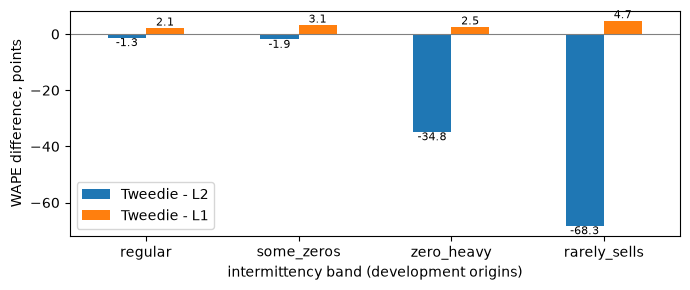

In [29]:
fig, ax = plt.subplots(figsize=(7, 3))
gap = pd.DataFrame({"Tweedie - L2": band_table["wape"]["Tweedie 1.3"] - band_table["wape"]["L2"],
                    "Tweedie - L1": band_table["wape"]["Tweedie 1.3"] - band_table["wape"]["L1"]}) * 100
gap.plot.bar(ax=ax, rot=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f", fontsize=8)
ax.axhline(0, color="grey", lw=0.8)
ax.set(xlabel="intermittency band (development origins)", ylabel="WAPE difference, points")
plt.tight_layout()

- **Tweedie does not get relatively better against L1 as intermittency rises.** It trails L1 in every band: by 2.1, 3.1, 2.5 and 4.7 points.
- **Against L2 it gains a lot in the zero-heavy bands** (35 and 68 points). That gain is raw L2 failing on small products, not Tweedie excelling.
- **Tweedie's advantage is bias.** Up to the zero-heavy band its bias stays within ±0.03, while L1 underforecasts more as zeros increase (-0.13, -0.17, -0.22). In the rarely-sells band every objective except L2 underforecasts heavily. Many of those products probably launch or restart inside the forecast window, which history cannot reveal.
- **L1 has the lowest WAPE in every band except rarely sells**, where the 0.6 quantile is 1.3 points ahead. The quantile otherwise behaves like Tweedie: near-zero bias, with WAPE between L1 and L2.
- The two zero-heavy bands hold about 2% of the units, so even large differences there move the aggregate little.

### One intermittent product

The intermittent example from section 2, chosen by its zero-sales share up to the last development cutoff, not by how the models did afterwards. Forecasts from that cutoff, with the 14-week totals in the legend.

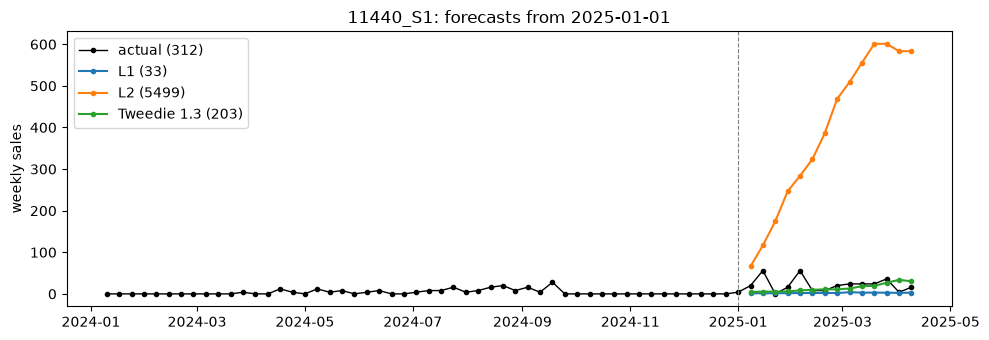

In [30]:
sku, cutoff = examples["intermittent"], DEV_CUTOFFS[-1]
window = actuals[(actuals.unique_id == sku) & (actuals.ds > cutoff - pd.Timedelta(weeks=52)) & (actuals.ds <= cutoff + pd.Timedelta(weeks=H))]
shown = raw[(raw.unique_id == sku) & (raw.cutoff == cutoff) & raw.model.isin(["lgbm_raw", "lgbm_l1_raw", "lgbm_tweedie_raw"])]
actual_total = window[window.ds > cutoff].y.sum()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(window.ds, window.y, marker=".", color="black", lw=1, label=f"actual ({actual_total:.0f})")
for model, rows in shown.groupby("model"):
    ax.plot(rows.ds, rows.yhat, marker=".", label=f"{OBJECTIVE[model]} ({rows.yhat.sum():.0f})")
ax.axvline(cutoff, color="grey", ls="--", lw=0.8)
ax.set(title=f"{sku}: forecasts from {cutoff:%Y-%m-%d}", ylabel="weekly sales")
ax.legend()
plt.tight_layout()

On this product Tweedie's 14-week total (203) is closest to the actual 312. L1 forecasts about 2 a week, the median of a mostly-zero history. Raw L2 climbs to about 600 a week, which is the raw-L2 low-volume failure at its most extreme. The product illustrates the bias pattern in the table: the median of an intermittent history is near zero, but the mean is not. It does not reverse the WAPE ranking for the band as a whole.

### Would more intermittent data favor a different objective?

**Evidence from this data.** L1 has the lowest WAPE in three of the four bands, including zero heavy, and the 0.6 quantile edges it in the fourth. Tweedie is never best on WAPE. As zeros increase, L1's bias becomes more negative, while Tweedie's stays near zero until the rarely-sells band.

**Hypothesis, not tested here.** Tweedie or a higher quantile could be the better choice in two situations: a portfolio where intermittent products carry much of the volume, or a metric that penalizes bias, such as a fill-rate or stock target. In both, L1's growing underforecast would carry real weight. Our sample cannot test this, because its zero-heavy products are 2% of the units. A test would need a dataset, or a reweighted evaluation, in which intermittent demand matters.

## 6. Objectives with target standardization

Notebook 02 standardized each product's target, `(y - mean) / std` with `LocalStandardScaler`, and found it much better than raw units for L2. Standardizing also changes what each objective weighs:

- On raw units, a miss of 100 units counts the same on any product, so the large products dominate the loss. On z-scores, each product's misses are divided by its own standard deviation, so every product counts roughly equally.
- L2 squares those misses, so the reweighting changes it the most. L1 and the quantile loss grow only linearly with the miss and are already less dominated by the large products.

Same configuration again, with the scaler added. The L2 version is `lgbm_baseline` from notebook 02. Tweedie is left out: the standardized target is negative for about half the weeks (section 3).

In [31]:
mlf_std = MLForecast(
    models={
        # "lgbm_baseline": lgb.LGBMRegressor(**LGB_PARAMS),  L2, fit in notebook 02
        "lgbm_l1_std": lgb.LGBMRegressor(**LGB_PARAMS, objective="l1"),
        "lgbm_quantile60_std": lgb.LGBMRegressor(**LGB_PARAMS, objective="quantile", alpha=0.6),
    },
    freq=FREQ,
    lags=LAGS,
    lag_transforms=LAG_TRANSFORMS,
    date_features=DATE_FEATURES,
    target_transforms=[LocalStandardScaler()],
    num_threads=1,
)

In [32]:
start = time.perf_counter()
std_forecasts = []
for cutoff in ALL_CUTOFFS:
    mlf_std.fit(actuals[actuals.ds <= cutoff])
    std_forecasts.append(to_long(mlf_std.predict(H), cutoff, "06_objectives"))
std_forecasts = pd.concat(std_forecasts)
print(f"{time.perf_counter() - start:.0f} s for two models at {len(ALL_CUTOFFS)} origins")

16 s for two models at 10 origins


Raw and standardized side by side. `change` is standardized minus raw, in WAPE points.

In [33]:
PAIRS = {"L2": ("lgbm_raw", "lgbm_baseline"), "L1": ("lgbm_l1_raw", "lgbm_l1_std"), "quantile 0.6": ("lgbm_quantile60_raw", "lgbm_quantile60_std")}
scaled = pd.concat([raw, load_forecasts(["02_ml_baseline"]).query("model == 'lgbm_baseline'"), std_forecasts])
dev = leaderboard(scaled, actuals, scope="dev").set_index("model")
final = leaderboard(scaled, actuals, scope="test").set_index("model")

rows = []
for objective, (raw_model, std_model) in PAIRS.items():
    for target, model in [("raw", raw_model), ("standardized", std_model)]:
        rows.append({"objective": objective, "target": target, "wape": dev.wape[model], "bias": dev.bias[model],
                     "mean_rmsse": dev.mean_rmsse[model], "median_rmsse": dev.median_rmsse[model], "final_wape": final.wape[model]})
scale_table = pd.DataFrame(rows).pivot(index="objective", columns="target").loc[list(PAIRS)]
scale_table[("wape", "change")] = (scale_table[("wape", "standardized")] - scale_table[("wape", "raw")]) * 100
scale_table[["wape", "bias", "mean_rmsse", "median_rmsse", "final_wape"]].round(3)

wape                       bias              mean_rmsse  \
target          raw standardized change    raw standardized        raw   
objective                                                                
L2            0.456        0.449 -0.658  0.044        0.139      5.501   
L1            0.409        0.378 -3.083 -0.143       -0.039      1.757   
quantile 0.6  0.433        0.440  0.751 -0.006        0.149      1.839   

                          median_rmsse              final_wape               
target       standardized          raw standardized        raw standardized  
objective                                                                    
L2                  1.865        1.224        0.921      0.505        0.419  
L1                  1.705        0.858        0.833      0.375        0.369  
quantile 0.6        1.802        0.940        0.942      0.433        0.450

### Observations

- Standardization substantially improves L2's final WAPE
  and reduces its mean RMSSE.
- L1 benefits from standardization in both accuracy and bias
  across development windows.
- Quantile loss does not benefit from standardization
  on this dataset.

Target scaling and objective selection are complementary
techniques, but their interaction should be tested.

Save the forecasts of sections 4 and 6. The four models notebook 06 has always produced go to `06_objectives`, which notebooks 07 and 08 read. The new raw-target quantile model goes to its own file, `06_raw_quantile`, so the model-selection pools of notebook 07 stay as they were.

In [34]:
objective_forecasts = pd.concat([raw_forecasts, std_forecasts])
new = objective_forecasts.model == "lgbm_quantile60_raw"
save_forecasts(objective_forecasts[~new], "06_objectives")
save_forecasts(objective_forecasts[new].assign(experiment="06_raw_quantile"), "06_raw_quantile")

## 7. L1 in our forecasting system

Notebook 03 kept the L2 objective of the 02 baseline, so its comparisons changed only the drivers. Here its three main models are refit with L1, everything else identical: the same features, target standardization, lags, parameters and origins. With the history-only pair from section 6, that gives four configurations:

| information | L2 | L1 |
|---|---|---|
| sales history and calendar | `lgbm_baseline` (02) | `lgbm_l1_std` (section 6) |
| + product attributes | `lgbm_categorical` (03) | `lgbm_l1_std_categorical` |
| + historical price and promotion drivers | `lgbm_hist_drivers` (03) | `lgbm_l1_hist_drivers` |
| + the full price and promotion plan | `lgbm_future_price_levels` (03) | `lgbm_l1_future_price_levels` |

The L1 models are candidates for notebook 07, each in the scenario its information allows. About two minutes.

In [35]:
from shared.features import CATEGORICAL, HISTORICAL, PROMO_CALENDAR, add_drivers, item_attributes, future_drivers, historical_drivers

panel = add_drivers(panel)
attributes = item_attributes(panel)
as_category = {col: "category" for col in CATEGORICAL}
drivers = future_drivers(panel)
hist = historical_drivers(panel)
plan_cols = PROMO_CALENDAR + ["discount", "price_index", "regular_price", "planned_price"]   # lgbm_future_price_levels, chosen in notebook 03

Product attributes: department, class and subclass as categorical features.

In [36]:
l1_feature_forecasts = []
for cutoff in ALL_CUTOFFS:
    train = actuals[actuals.ds <= cutoff].merge(attributes, on="unique_id").astype(as_category)
    mlf = MLForecast(
        models={"lgbm_l1_std_categorical": lgb.LGBMRegressor(**LGB_PARAMS, objective="l1")},
        freq=FREQ, lags=LAGS, lag_transforms=LAG_TRANSFORMS, date_features=DATE_FEATURES,
        target_transforms=[LocalStandardScaler()], num_threads=1,
    )
    mlf.fit(train, static_features=CATEGORICAL)
    l1_feature_forecasts.append(to_long(mlf.predict(H), cutoff, "06_l1_features", "history"))

Plus historical price and promotion drivers. In the forecast weeks the regular price is carried forward from the cutoff; nothing about the future plan is used.

In [37]:
for cutoff in ALL_CUTOFFS:
    train = (actuals[actuals.ds <= cutoff].merge(hist[["unique_id", "ds", *HISTORICAL]], on=["unique_id", "ds"])
             .merge(attributes, on="unique_id").astype(as_category))
    X_df = hist.loc[(hist.ds > cutoff) & (hist.ds <= cutoff + pd.Timedelta(weeks=H)), ["unique_id", "ds", *HISTORICAL]].copy()
    X_df["regular_price"] = X_df.unique_id.map(hist[hist.ds <= cutoff].groupby("unique_id").regular_price.last())
    mlf = MLForecast(
        models={"lgbm_l1_hist_drivers": lgb.LGBMRegressor(**LGB_PARAMS, objective="l1")},
        freq=FREQ, lags=LAGS, lag_transforms=LAG_TRANSFORMS, date_features=DATE_FEATURES,
        target_transforms=[LocalStandardScaler()], num_threads=1,
    )
    mlf.fit(train, static_features=CATEGORICAL)
    l1_feature_forecasts.append(to_long(mlf.predict(H, X_df=X_df), cutoff, "06_l1_features", "historical_drivers"))

Plus the full price and promotion plan for every forecast week.

In [38]:
for cutoff in ALL_CUTOFFS:
    train = (actuals[actuals.ds <= cutoff].merge(drivers[["unique_id", "ds", *plan_cols]], on=["unique_id", "ds"])
             .merge(attributes, on="unique_id").astype(as_category))
    X_df = drivers.loc[(drivers.ds > cutoff) & (drivers.ds <= cutoff + pd.Timedelta(weeks=H)), ["unique_id", "ds", *plan_cols]]
    mlf = MLForecast(
        models={"lgbm_l1_future_price_levels": lgb.LGBMRegressor(**LGB_PARAMS, objective="l1")},
        freq=FREQ, lags=LAGS, lag_transforms=LAG_TRANSFORMS, date_features=DATE_FEATURES,
        target_transforms=[LocalStandardScaler()], num_threads=1,
    )
    mlf.fit(train, static_features=CATEGORICAL)
    l1_feature_forecasts.append(to_long(mlf.predict(H, X_df=X_df), cutoff, "06_l1_features", "future_drivers"))

l1_feature_forecasts = pd.concat(l1_feature_forecasts)

Each L1 model against its L2 version, on identical rows. `change` is in WAPE points; `better_at` counts the seven development origins where L1 wins.

In [39]:
SYSTEM = {
    "sales history and calendar": ("lgbm_baseline", "lgbm_l1_std"),
    "+ product attributes": ("lgbm_categorical", "lgbm_l1_std_categorical"),
    "+ historical drivers": ("lgbm_hist_drivers", "lgbm_l1_hist_drivers"),
    "+ full price and promotion plan": ("lgbm_future_price_levels", "lgbm_l1_future_price_levels"),
}
l2_models = [l2 for l2, _ in SYSTEM.values()]
system = pd.concat([load_forecasts(["02_ml_baseline", "03_exogenous"]).query("model in @l2_models"), std_forecasts.query("model == 'lgbm_l1_std'"), l1_feature_forecasts])
dev = leaderboard(system, actuals, scope="dev").set_index("model")
final = leaderboard(system, actuals, scope="test").set_index("model")
origin_wape = score(system[system.cutoff.isin(DEV_CUTOFFS)], actuals, by=["cutoff"], rmsse=False).pivot(index="model", columns="cutoff", values="wape")

pd.DataFrame({
    "dev_wape_l2": [dev.wape[l2] for l2, l1 in SYSTEM.values()],
    "dev_wape_l1": [dev.wape[l1] for l2, l1 in SYSTEM.values()],
    "change": [(dev.wape[l1] - dev.wape[l2]) * 100 for l2, l1 in SYSTEM.values()],
    "better_at": [int((origin_wape.loc[l1] < origin_wape.loc[l2]).sum()) for l2, l1 in SYSTEM.values()],
    "dev_bias_l2": [dev.bias[l2] for l2, l1 in SYSTEM.values()],
    "dev_bias_l1": [dev.bias[l1] for l2, l1 in SYSTEM.values()],
    "final_wape_l2": [final.wape[l2] for l2, l1 in SYSTEM.values()],
    "final_wape_l1": [final.wape[l1] for l2, l1 in SYSTEM.values()],
}, index=list(SYSTEM)).round(3)

,dev_wape_l2,dev_wape_l1,change,better_at,dev_bias_l2,dev_bias_l1,final_wape_l2,final_wape_l1
sales history and calendar,0.449,0.378,-7.146,7,0.139,-0.039,0.419,0.369
+ product attributes,0.423,0.359,-6.485,7,0.102,-0.072,0.400,0.350
+ historical drivers,0.416,0.355,-6.106,7,0.091,-0.076,0.396,0.349
+ full price and promotion plan,0.311,0.291,-1.958,7,0.069,0.002,0.278,0.268


- **L1 improves all four configurations at every development origin.** The gain is 7.1 points with sales history only, 6.5 with product attributes, 6.1 with historical drivers and 2.0 with the full plan. The final window agrees: 0.419 to 0.369, 0.400 to 0.350, 0.396 to 0.349 and 0.278 to 0.268.
- **The gain shrinks as the drivers explain more of the variation.** L1 helps because L2 raises ordinary weeks towards spikes it cannot explain (section 1). Historical drivers explain little of that: the L2 bias falls only from +0.139 to +0.091. The price and promotion plan tells the model which weeks will spike, so those weeks get their own situations. The conditional mean and median then move closer together: L2's overforecast drops to +0.069, L1's bias to +0.002, and the objective has less left to correct.
- L1 with the full plan is the best individual model of Day 1 (0.291 on development, 0.268 in the final window).

In [40]:
save_forecasts(l1_feature_forecasts, "06_l1_features")

## Summary

- **The objective decides what a model aims for.** L2 aims at the conditional mean and L1 at the conditional median. A quantile loss aims at a chosen quantile, and Tweedie at the mean, under a variance that grows with the level.
- **Our demand is right-skewed within products, and a sixth of the products are mostly zeros.** Those products carry under 2% of the units, so the regular products decide aggregate WAPE.
- **WAPE rewards L1, and L1 has the lowest WAPE in almost every comparison here:** overall, in three of four intermittency bands, raw or standardized, and with every feature set. The price is underforecasting, which is worst on intermittent products. Tweedie and the 0.6 quantile keep bias near zero at a higher WAPE.
- **L1 matters most when the features cannot explain the spikes.** With the promotion plan, its gain falls to 2 points.

To try later: change `tweedie_variance_power` (between 1 and 2) or the quantile `alpha`. An earlier experiment that gave Tweedie a non-negative per-product scale (`y / max(y)`) is in `experiments/06_max_scaling/`. It made Tweedie worse.